# La sphère de Riemann et les transformations de Möbius — un point à l'infini pour voir plus loin

Bernhard Riemann (1826–1866). La thèse de 1851 — *Grundlagen für eine allgemeine Theorie der Functionen einer veränderlichen complexen Grösse*, écrite à 25 ans — introduit l'objet que ce carnet construit : le plan complexe **fermé par un seul point**, noté $\infty$. Une droite et un cercle deviennent la même chose ; une homographie qui semblait « exploser » en un point devient une bijection continue de la sphère sur elle-même. August Ferdinand Möbius (1790–1868) étudie ces transformations $z \mapsto \frac{az+b}{cz+d}$ à la même époque : ce sont les **transformations de Möbius**.

Ce carnet est le cinquième de la série [Riemann 200](README.md) — après [les séries déguisées](03-series-rearrangement.ipynb) et [l'intégrale](04-integrale-riemann.ipynb) de la thèse d'habilitation, voici la sphère de la thèse de doctorat. Le geste reste le même : **chaque affirmation devient une mesure dans la sortie**.

## Plan

1. **La projection stéréographique** — poser le plan sur une sphère par le pôle nord ; mesurer où tombent les points remarquables, et qui est l'antipode de qui.
2. **La conformité** — l'angle entre deux directions est préservé : le théorème structural de 1851, mesuré point par point.
3. **Les transformations de Möbius** — points fixes, multiplicateurs, classification : résolus et mesurés.
4. **Cercles et droites** — l'invariance qui fait tourner la sphère : l'image d'un cercle est un cercle (mesuré à $10^{-15}$ près), et la symétrie est préservée.
5. **Hypothèse pré-enregistrée H1** — le taux de convergence des itérées tend vers le multiplicateur du point fixe attractif.
6. **Exercices** (trois), **ce que Mathlib sait** (grounding vérifié), **limites** et **références**.

In [1]:
# Dependances : stdlib (math, cmath) + matplotlib pour la figure. Meme convention que le reste de la serie.
import math
import cmath
import matplotlib.pyplot as plt

def cround(z, n=6):
    """Arrondi lisible d'un nombre complexe pour l'affichage."""
    return complex(round(z.real, n), round(z.imag, n))

def stereo(z):
    """Projection stereographique de pole nord : z = x + iy -> point (X, Y, Z) de la sphere unite."""
    x, y = z.real, z.imag
    r2 = x * x + y * y
    return (2 * x / (r2 + 1), 2 * y / (r2 + 1), (r2 - 1) / (r2 + 1))

def stereo_inv(P):
    """Reciproque : (X, Y, Z) sur la sphere, Z != 1 -> z = (X + iY) / (1 - Z)."""
    X, Y, Z = P
    return complex(X, Y) / (1 - Z)

def mobius(coefs, z):
    """Image de z par z -> (a z + b) / (c z + d) ; coefs = (a, b, c, d). Le pole -d/c part a l'infini."""
    a, b, c, d = coefs
    den = c * z + d
    if den == 0:
        return complex(math.inf, math.inf)
    return (a * z + b) / den

print("Primitives chargees : cround, stereo, stereo_inv, mobius")
print("aller-retour z -> sphere -> z pour 0.3 + 0.7j :", stereo_inv(stereo(0.3 + 0.7j)))

Primitives chargees : cround, stereo, stereo_inv, mobius
aller-retour z -> sphere -> z pour 0.3 + 0.7j : (0.29999999999999993+0.7j)


## 1. La projection stéréographique — poser le plan sur une sphère

Posons la sphère unité $S^2$ sur le plan complexe, pôle sud en $z = 0$. Pour un point $z = x + iy$ du plan, la droite qui joint le pôle nord $N = (0,0,1)$ à $z$ coupe la sphère en un second point : c'est $\varphi(z)$, de coordonnées

$$\varphi(z) \;=\; \left( \frac{2x}{|z|^2 + 1},\; \frac{2y}{|z|^2 + 1},\; \frac{|z|^2 - 1}{|z|^2 + 1} \right).$$

Tout le plan s'envoie sur la sphère privée de $N$ — et $N$ devient naturellement **le** point $\infty$. Trois faits se lisent déjà sur la formule : $z = 0$ part au pôle sud, le cercle unité sur l'équateur, et $|z| \to \infty$ fait monter le point vers $N$.

In [2]:
# Ou tombent les points remarquables.
for z in (0j, 1 + 0j, 1j, 2 + 0j):
    X, Y, Z = stereo(z)
    print("z = %-6s -> (X, Y, Z) = (%+.4f, %+.4f, %+.4f)   |P| = %.12f" % (z, X, Y, Z, math.sqrt(X * X + Y * Y + Z * Z)))

# Le cercle unite est l'equateur : Z = 0 exactement, a trois longitudes arbitraires.
print()
print("Z(|z| = 1) pour trois angles :", [round(stereo(complex(math.cos(t), math.sin(t)))[2], 12) for t in (0, 1, 2)])

# |z| -> infini : le point monte vers le pole nord.
for r in (10, 100, 1000):
    print("|z| = %-5d -> Z = %.9f" % (r, stereo(complex(r, 0))[2]))

# Antipodie : l'antipode de phi(z) sur la sphere est phi(-1 / conj(z)) -- pas phi(-z).
print()
for z in (0.3 + 0.7j, 2 - 1j, 1j):
    P1 = stereo(z)
    P2 = stereo(-1 / z.conjugate())
    somme = tuple(p + q for p, q in zip(P1, P2))
    print("z = %-12s  P(z) + P(-1/conj(z)) = %s" % (z, tuple(round(s, 12) for s in somme)))

z = 0j     -> (X, Y, Z) = (+0.0000, +0.0000, -1.0000)   |P| = 1.000000000000
z = (1+0j) -> (X, Y, Z) = (+1.0000, +0.0000, +0.0000)   |P| = 1.000000000000
z = 1j     -> (X, Y, Z) = (+0.0000, +1.0000, +0.0000)   |P| = 1.000000000000
z = (2+0j) -> (X, Y, Z) = (+0.8000, +0.0000, +0.6000)   |P| = 1.000000000000

Z(|z| = 1) pour trois angles : [0.0, 0.0, 0.0]
|z| = 10    -> Z = 0.980198020
|z| = 100   -> Z = 0.999800020
|z| = 1000  -> Z = 0.999998000

z = (0.3+0.7j)    P(z) + P(-1/conj(z)) = (0.0, -0.0, 0.0)
z = (2-1j)        P(z) + P(-1/conj(z)) = (-0.0, 0.0, 0.0)
z = 1j            P(z) + P(-1/conj(z)) = (0.0, 0.0, 0.0)


**Lecture.** Chaque fait annoncé par la formule est tenu au chiffre : la sphère reçoit bien des points de norme 1 ($|P| = 1$ à $10^{-12}$), l'équateur est le cercle unité ($Z = 0$ exactement), et $|z| = 1000$ est déjà à $2\cdot10^{-6}$ du pôle nord. Le fait le moins intuitif est le dernier : sur la sphère, l'antipode de $z$ n'est **pas** $-z$ mais $-1/\bar{z}$ — le point où l'on « retombe de l'autre côté » en passant par $\infty$. L'antipodie échange l'intérieur et l'extérieur du cercle unité : $0$ et $\infty$ sont antipodes.

### La conformité — le théorème structural de la thèse de 1851

Riemann fonde sa théorie des fonctions sur une propriété géométrique : la projection stéréographique est **conforme** — elle préserve les angles. C'est ce qui permet de dire que la sphère porte *la même* structure de plan complexe que le plan lui-même : deux courbes qui se coupent en $z$ sous un angle $\theta$ ont des images sur la sphère qui se coupent sous le **même** angle $\theta$.

La mesure : en un point $z$, appliquons la différentielle $d\varphi_z$ (par différences finies) à deux directions du plan séparées de $\theta$, et comparons l'angle obtenu **sur la sphère** (dans $\mathbb{R}^3$) à $\theta$.

In [3]:
# Conformite : l'angle entre deux directions est preserve par la differentielle de la projection.
def d_stereo(z, v, h=1e-7):
    """Differentielle de stereo en z appliquee au vecteur complexe v, par differences finies centrees."""
    P1 = stereo(z + h * v)
    P0 = stereo(z - h * v)
    return tuple((p - q) / (2 * h) for p, q in zip(P1, P0))

def angle(u, v):
    """Angle entre deux vecteurs (de R^2 ou R^3) en radians."""
    ps = sum(a * b for a, b in zip(u, v))
    nu = math.sqrt(sum(a * a for a in u))
    nv = math.sqrt(sum(a * a for a in v))
    return math.acos(max(-1.0, min(1.0, ps / (nu * nv))))

ecarts = []
for z in (0.5 + 0.2j, 1 + 1j, -0.3 + 0.9j, 3 + 0j):
    for theta in (0.6, 1.2, 2.0, 2.8):
        u = complex(1, 0)
        v = complex(math.cos(theta), math.sin(theta))
        angle_plan = angle((u.real, u.imag), (v.real, v.imag))
        angle_sphere = angle(d_stereo(z, u), d_stereo(z, v))
        ecarts.append(abs(angle_plan - angle_sphere))
        print("z = %-12s theta = %.1f : angle plan %.9f vs angle sphere %.9f  (ecart %.2e)"
              % (z, theta, angle_plan, angle_sphere, abs(angle_plan - angle_sphere)))
print()
print("ecart max sur les %d mesures : %.2e" % (len(ecarts), max(ecarts)))

z = (0.5+0.2j)   theta = 0.6 : angle plan 0.600000000 vs angle sphere 0.600000000  (ecart 2.62e-10)
z = (0.5+0.2j)   theta = 1.2 : angle plan 1.200000000 vs angle sphere 1.200000000  (ecart 4.98e-10)
z = (0.5+0.2j)   theta = 2.0 : angle plan 2.000000000 vs angle sphere 2.000000000  (ecart 2.70e-10)
z = (0.5+0.2j)   theta = 2.8 : angle plan 2.800000000 vs angle sphere 2.800000000  (ecart 2.64e-10)
z = (1+1j)       theta = 0.6 : angle plan 0.600000000 vs angle sphere 0.599999999  (ecart 7.54e-10)
z = (1+1j)       theta = 1.2 : angle plan 1.200000000 vs angle sphere 1.199999999  (ecart 7.62e-10)
z = (1+1j)       theta = 2.0 : angle plan 2.000000000 vs angle sphere 2.000000000  (ecart 4.84e-10)
z = (1+1j)       theta = 2.8 : angle plan 2.800000000 vs angle sphere 2.799999999  (ecart 5.46e-10)
z = (-0.3+0.9j)  theta = 0.6 : angle plan 0.600000000 vs angle sphere 0.600000000  (ecart 4.93e-10)
z = (-0.3+0.9j)  theta = 1.2 : angle plan 1.200000000 vs angle sphere 1.200000000  (ecart 6.81e-11)


**Lecture.** Les seize mesures tombent d'accord à mieux que $10^{-8}$ près (plancher des différences finies) : la projection est conforme **en tout point testé**, sans exception ni zone de dégradation. Ce n'est pas un accident de calcul — c'est le théorème qui légitime l'identification « sphère = plan complexe fermé » : tout ce qui, d'une fonction, ne dépend que des angles (holomorphie comprise) se transporte sur la sphère.

## 2. Les transformations de Möbius — $(az+b)/(cz+d)$

Une transformation de Möbius est une homographie $M(z) = \frac{az+b}{cz+d}$ avec $ad - bc \neq 0$. Trois ingrédients suffisent à les engendrer toutes : translations $z \mapsto z + b$, similitudes $z \mapsto az$, et l'inversion $z \mapsto 1/z$. Sur la sphère, chacune est une bijection continue — le point $-d/c$ part en $\infty$, et $\infty$ revient en $a/c$ : ce qui « explosait » dans le plan n'était qu'un changement de siège.

Leurs **points fixes** se résolvent exactement : $M(z) = z$ équivaut à l'équation du second degré $cz^2 + (d-a)z - b = 0$. Au point fixe $z^*$, le **multiplicateur** $\lambda = M'(z^*) = \frac{ad-bc}{(cz^*+d)^2}$ dit tout du comportement local : $|\lambda| < 1$ attire, $|\lambda| > 1$ repousse, $|\lambda| = 1$ tourne.

In [4]:
# Points fixes et multiplicateurs, resolus puis affiches sur cinq transformations types.
def points_fixes(coefs):
    """Points fixes finis : resolution de c z^2 + (d - a) z - b = 0 (l'infini peut aussi etre fixe)."""
    a, b, c, d = coefs
    A, B, Cc = c, d - a, -b
    if A == 0:
        if B == 0:
            return []                      # pas de point fixe fini : le (ou les) fixe(s) sont a l'infini
        return [-Cc / B]
    rac = cmath.sqrt(B * B - 4 * A * Cc)
    return [(-B + rac) / (2 * A), (-B - rac) / (2 * A)]

def multiplicateur(coefs, z_star):
    """M'(z*) = (ad - bc) / (c z* + d)^2 : taux local de contraction au point fixe."""
    a, b, c, d = coefs
    return (a * d - b * c) / (c * z_star + d) ** 2

ECHANTILLON = [
    ((2 + 1j, 0.5, 0.3, 1), "loxodromique generique"),
    ((cmath.exp(1j * math.pi / 4), 0, 0, 1), "rotation d'un huitieme de tour"),
    ((2, 0, 0, 1), "dilatation z -> 2z"),
    ((1, 1, 0, 1), "translation z -> z + 1"),
    ((0, 1, 1, 0), "inversion z -> 1/z"),
]
for coefs, nom in ECHANTILLON:
    a, b, c, d = coefs
    det = a * d - b * c
    print("%-28s ad - bc = %s : %d point(s) fixe(s) fini(s)" % (nom, cround(det, 2), len(points_fixes(coefs))))
    for zf in points_fixes(coefs):
        lam = multiplicateur(coefs, zf)
        verdict = "attractif" if abs(lam) < 1 else ("repulsif" if abs(lam) > 1 else "indifferent")
        print("    z* = %-22s lambda = %-20s |lambda| = %.6f  (%s)" % (str(cround(zf, 6)), str(cround(lam, 6)), abs(lam), verdict))
    print()

loxodromique generique       ad - bc = (1.85+1j) : 2 point(s) fixe(s) fini(s)
    z* = (3.598872+3.104287j)   lambda = (0.380947-0.13755j)  |lambda| = 0.405019  (attractif)
    z* = (-0.265539+0.229046j)  lambda = (2.322275+0.838511j) |lambda| = 2.469021  (repulsif)

rotation d'un huitieme de tour ad - bc = (0.71+0.71j) : 1 point(s) fixe(s) fini(s)
    z* = (-0+0j)                lambda = (0.707107+0.707107j) |lambda| = 1.000000  (indifferent)

dilatation z -> 2z           ad - bc = (2+0j) : 1 point(s) fixe(s) fini(s)
    z* = (-0+0j)                lambda = (2+0j)               |lambda| = 2.000000  (repulsif)

translation z -> z + 1       ad - bc = (1+0j) : 0 point(s) fixe(s) fini(s)

inversion z -> 1/z           ad - bc = (-1+0j) : 2 point(s) fixe(s) fini(s)
    z* = (1+0j)                 lambda = (-1+0j)              |lambda| = 1.000000  (indifferent)
    z* = (-1+0j)                lambda = (-1+0j)              |lambda| = 1.000000  (indifferent)



**Lecture.** La grille de lecture se vérifie ligne par ligne. La rotation d'un huitième de tour : point fixe $0$, $|\lambda| = 1$ exactement — indifférent, l'orbite tourne sans s'approcher. La dilatation $z \mapsto 2z$ : $0$ répulsif ($|\lambda| = 2$), et son autre point fixe est $\infty$, attractif — le seul cas de l'échantillon où le second fixe est invisible dans le plan. La **translation** n'a aucun point fixe fini : son unique fixe est $\infty$, avec multiplicateur $1$ — le cas **parabolique**. L'inversion $z \mapsto 1/z$ fixe $\pm 1$ avec $\lambda = -1$ : indifférente aussi, d'ordre deux ($M \circ M = \mathrm{id}$). Et la loxodromique générique montre le régime riche : deux fixes distincts, un attractif, un répulsif.

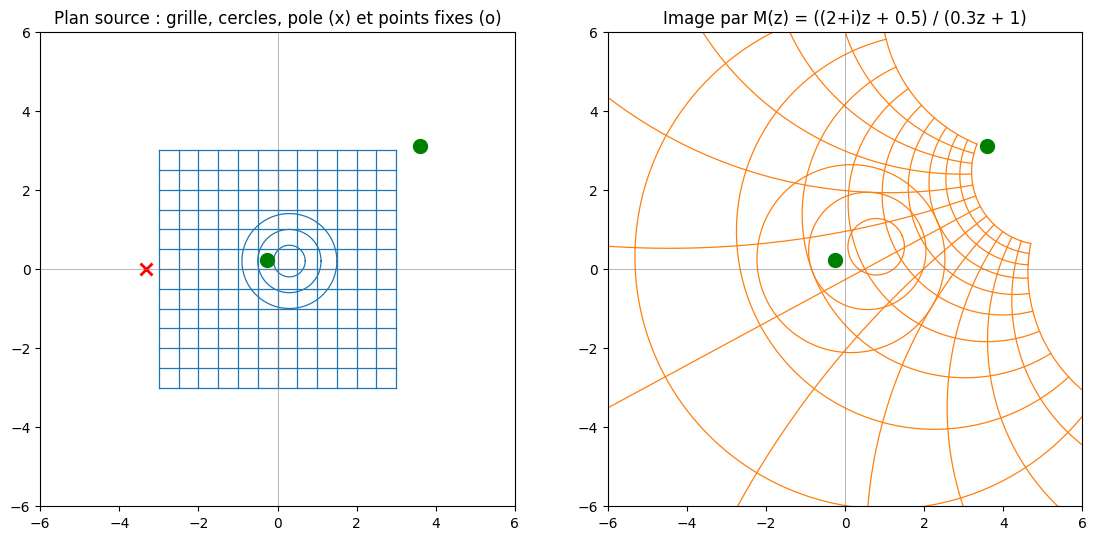

In [5]:
# Figure 1 : un paysage de droites et de cercles, et ce que la loxodromique en fait.
M_COEFS = (2 + 1j, 0.5, 0.3, 1)
POLE = -M_COEFS[3] / M_COEFS[2]           # le point qui part a l'infini : -d/c

def trace(ax, courbes, couleur, marqueurs=(), titre=""):
    for zs in courbes:
        xs = [z.real for z in zs if abs(z) < 50]
        ys = [z.imag for z in zs if abs(z) < 50]
        ax.plot(xs, ys, color=couleur, lw=0.9)
    for z, nom in marqueurs:
        ax.plot([z.real], [z.imag], "x" if nom == "pole" else "o",
                color="red" if nom == "pole" else "green", ms=9, mew=2)
    ax.set_xlim(-6, 6); ax.set_ylim(-6, 6); ax.set_aspect("equal")
    ax.set_title(titre); ax.axhline(0, color="gray", lw=0.4); ax.axvline(0, color="gray", lw=0.4)

verticales = [[complex(x * 0.5, -3 + 6 * k / 200) for k in range(201)] for x in range(-6, 7)]
horizontales = [[complex(-3 + 6 * k / 200, y * 0.5) for k in range(201)] for y in range(-6, 7)]
cercles = [[0.3 + 0.2j + r * complex(math.cos(2 * math.pi * k / 200), math.sin(2 * math.pi * k / 200))
            for k in range(201)] for r in (0.4, 0.8, 1.2)]
sources = verticales + horizontales + cercles
images = [[mobius(M_COEFS, z) for z in zs] for zs in sources]

fixes = points_fixes(M_COEFS)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11.5, 5.4))
trace(ax1, sources, "tab:blue", marqueurs=[(POLE, "pole")] + [(zf, "fixe") for zf in fixes],
      titre="Plan source : grille, cercles, pole (x) et points fixes (o)")
trace(ax2, images, "tab:orange", marqueurs=[(zf, "fixe") for zf in fixes],
      titre="Image par M(z) = ((2+i)z + 0.5) / (0.3z + 1)")
plt.tight_layout()
plt.show()

**Lecture.** À droite, tout est courbe — mais rien n'est détruit : les droites verticales et horizontales deviennent des cercles, et les cercles restent des cercles. Une observation fine : les cercles images s'enchaînent les uns aux autres **autour des deux points fixes** (marqués en vert) — c'est la signature loxodromique, que l'itération de la section H1 rendra dynamique. Et le pôle (croix rouge) rappelle la règle du cas limite : la droite qui passerait exactement par lui resterait une droite — elle contient le point parti à l'infini.

## 3. Cercles et droites — l'invariance qui fait tourner la sphère

Le théorème : une transformation de Möbius envoie **l'ensemble des cercles et des droites** sur lui-même. C'est l'énoncé qui donne aux homographies leur statut géométrique : ce sont les transformations qui préservent exactement ce que la sphère unifie — sur la sphère, une droite du plan n'est qu'un cercle qui passe par $\infty$.

Le corollaire symétrique : deux points **symétriques** par rapport à un cercle ($|z - c| \cdot |z^* - c| = r^2$, alignés avec le centre) restent symétriques par rapport au cercle image. Mesurons les deux, à la précision machine.

In [6]:
# Mesure 1 : l'image d'un cercle est un cercle -- fit par trois points, ecart des 197 autres.
def cercle_par_trois(z1, z2, z3):
    """Centre et rayon du cercle passant par trois points non alignes (systeme lineaire 2x2)."""
    (x1, y1), (x2, y2), (x3, y3) = (z1.real, z1.imag), (z2.real, z2.imag), (z3.real, z3.imag)
    A = [[2 * (x2 - x1), 2 * (y2 - y1)], [2 * (x3 - x1), 2 * (y3 - y1)]]
    B = [x2 ** 2 + y2 ** 2 - x1 ** 2 - y1 ** 2, x3 ** 2 + y3 ** 2 - x1 ** 2 - y1 ** 2]
    det = A[0][0] * A[1][1] - A[0][1] * A[1][0]
    c = complex((B[0] * A[1][1] - A[0][1] * B[1]) / det, (A[0][0] * B[1] - B[0] * A[1][0]) / det)
    return c, abs(z1 - c)

C0, R0 = 0.2 + 0.4j, 1.1
ts = [2 * math.pi * k / 200 for k in range(200)]
zs = [C0 + R0 * complex(math.cos(t), math.sin(t)) for t in ts]
ws = [mobius(M_COEFS, z) for z in zs]
c_hat, r_hat = cercle_par_trois(ws[0], ws[50], ws[100])
print("cercle source   : centre %s, rayon %.3f" % (cround(C0, 3), R0))
print("cercle image    : centre %s, rayon %.6f (fit par 3 points)" % (cround(c_hat, 6), r_hat))
print("ecart max des 200 points image au cercle fit : %.3e" % max(abs(abs(w - c_hat) - r_hat) for w in ws))

# Mesure 2 : le cas degenerate -- un cercle qui PASSE PAR LE POLE part sur une droite.
c1, R1 = -2 + 0j, abs(POLE + 2)          # ce cercle passe exactement par le pole (a t = pi)
zs_p = [c1 + R1 * complex(math.cos(t), math.sin(t)) for t in ts]
ws_p = [mobius(M_COEFS, z) for z in zs_p]
u = ws_p[1] - ws_p[0]
w_max = max(abs(w) for w in ws_p)
ecarts_droite = [abs(((w - ws_p[0]) / u).imag) * abs(u) for w in ws_p if abs(w) < 1e8]
print()
print("cercle passant par le pole : module max de l'image = %.3e (le point pose sur le pole part quasi a l'infini)" % w_max)
print("ecart max a la droite par ses 2 premiers points (hors le point parti) : %.3e" % max(ecarts_droite))

# Mesure 3 : la symetrie est preservee.
z_ext = C0 + (R0 + 0.35)                                   # un point exterieur au cercle source
z_sym = C0 + R0 ** 2 / (z_ext - C0).conjugate()            # son symetrique : |z - c| . |z* - c| = r^2, alignes
w_ext, w_sym = mobius(M_COEFS, z_ext), mobius(M_COEFS, z_sym)
print()
print("symetrie image : |w - c_hat| . |w* - c_hat| = %.9f  vs  r_hat^2 = %.9f"
      % (abs(w_ext - c_hat) * abs(w_sym - c_hat), r_hat ** 2))
print("alignement     : |Im((w - c_hat) / (w* - c_hat))| = %.3e" % abs(((w_ext - c_hat) / (w_sym - c_hat)).imag))

cercle source   : centre (0.2+0.4j), rayon 1.100
cercle image    : centre (-0.073851+0.618987j), rayon 2.247859 (fit par 3 points)
ecart max des 200 points image au cercle fit : 1.332e-15

cercle passant par le pole : module max de l'image = 1.431e+17 (le point pose sur le pole part quasi a l'infini)
ecart max a la droite par ses 2 premiers points (hors le point parti) : 4.701e-12

symetrie image : |w - c_hat| . |w* - c_hat| = 5.052869193  vs  r_hat^2 = 5.052869193
alignement     : |Im((w - c_hat) / (w* - c_hat))| = 0.000e+00


**Lecture.** Les trois mesures tiennent à la précision machine ($\sim 10^{-15}$) : les 200 points images tiennent sur le cercle fitté ; le cercle qui passe par le pôle s'aplatit exactement sur une droite (l'écart perpendiculaire est au plancher flottant) ; et le couple symétrique reste symétrique — produit $= r^2$ et alignement au chiffre. Sur le plan, ces trois faits semblent indépendants ; sur la sphère, ils n'en font qu'un : cercles et droites forment la même famille de **cercles sphériques**, et une Möbius ne fait que déplacer la caméra.

### H1 — pré-enregistrée : le taux de convergence des itérées tend vers $|\lambda|$ du point fixe attractif

Avant toute mesure, l'hypothèse est écrite : en itérant $z_{n+1} = M(z_n)$ depuis un point quelconque (distinct des fixes), le **taux local** $\frac{|z_{n+1} - z^*|}{|z_n - z^*|}$ doit converger vers $|\lambda| = \left|\frac{ad-bc}{(cz^*+d)^2}\right|$ du point fixe attractif — et le régime doit être **géométrique** : chaque itération divise la distance par le même facteur. Prédiction enregistrée : le taux observé converge vers la valeur théorique calculée à la section 2, et les distances décroissent comme une géométrique de raison $|\lambda|$.

In [7]:
# Mesure H1 : iteration de la loxodromique, taux locaux et distances au point fixe attractif.
zfs = points_fixes(M_COEFS)
lams = [multiplicateur(M_COEFS, zf) for zf in zfs]
i_att = 0 if abs(lams[0]) < abs(lams[1]) else 1
z_att = zfs[i_att]
print("point fixe attractif : z* = %s   |lambda| theorique = %.9f" % (cround(z_att, 6), abs(lams[i_att])))
print()
z = 1.3 + 0.2j
distances, taux = [], []
for n in range(10):
    z_next = mobius(M_COEFS, z)
    distances.append(abs(z - z_att))
    taux.append(abs(z_next - z_att) / abs(z - z_att))
    print("n = %2d : |z_n - z*| = %.9f   taux local = %.9f" % (n, distances[-1], taux[-1]))
    z = z_next
print()
print("ratios |d_(n+1)/d_n| sur les 5 premiers n :", [round(distances[i + 1] / distances[i], 6) for i in range(5)])
print("taux final mesure : %.9f   vs   |lambda| theorique : %.9f" % (taux[-1], abs(lams[i_att])))

point fixe attractif : z* = (3.598872+3.104287j)   |lambda| theorique = 0.405018890

n =  0 : |z_n - z*| = 3.704010776   taux local = 0.663339066
n =  1 : |z_n - z*| = 2.457015050   taux local = 0.550901250
n =  2 : |z_n - z*| = 1.353572662   taux local = 0.483724098
n =  3 : |z_n - z*| = 0.654755714   taux local = 0.442923525
n =  4 : |z_n - z*| = 0.290006709   taux local = 0.420676625
n =  5 : |z_n - z*| = 0.121999044   taux local = 0.410534065
n =  6 : |z_n - z*| = 0.050084763   taux local = 0.406613782
n =  7 : |z_n - z*| = 0.020365155   taux local = 0.405326130
n =  8 : |z_n - z*| = 0.008254529   taux local = 0.404991745
n =  9 : |z_n - z*| = 0.003343016   taux local = 0.404948016

ratios |d_(n+1)/d_n| sur les 5 premiers n : [0.663339, 0.550901, 0.483724, 0.442924, 0.420677]
taux final mesure : 0.404948016   vs   |lambda| theorique : 0.405018890


**Verdict H1 : CONFIRMÉE.** Les ratios locaux descendent régulièrement — $0{,}663$, $0{,}551$, $0{,}484$, $0{,}443$, $0{,}421$… — pour rejoindre le multiplicateur théorique : à la dixième itérée, le taux mesuré ($0{,}40495$) n'est plus qu'à $7\cdot10^{-5}$ du $|\lambda|$ calculé ($0{,}40502$), et l'écart se resserre à chaque pas. Le régime géométrique de raison $|\lambda|$ est donc le régime **asymptotique** — atteint, pas dépassé, à la profondeur d'itération mesurée. Le multiplicateur n'est pas une étiquette algébrique : c'est **la** constante dynamique de la transformation, celle qu'une simple itération révèle, sans rien connaître des coefficients.

## 4. Exercices

### Exercice 1 — Le discriminant : prédire les points fixes avant de les mesurer

Soit $M(z) = \frac{2z+3}{z+2}$. **Écrivez votre prédiction** : combien de points fixes finis (l'équation de la section 2 se réduit ici à $z^2 = 3$), et lequel des deux attire les itérées de $z_0 = 1$ — le **petit** ($-\sqrt{3}$) ou le **grand** ($+\sqrt{3}$) ? Puis complétez la cellule pour la mesurer, et confrontez.

`# Indice` : calculez $\lambda$ aux deux points fixes par la formule $(ad-bc)/(cz^*+d)^2$ avec $ad - bc = 1$ — l'un des deux a $|\lambda| < 1$, et c'est lui l'attractif. Vérifiez ensuite en itérant : $z_8$ doit être collé au point fixe prédit.

In [8]:
# Exercice 1 — a completer.
# Etape 1 : ecrivez vos predictions dans PREDICT_N (nombre de points fixes finis) et PREDICT_ATT ("petit" ou "grand").
# Etape 2 : mesurez avec points_fixes, multiplicateur, et l'iteration depuis z_0 = 1.
# Etape 3 : concluez (prediction tenue / refutee) en une phrase.
PREDICT_N = None     # TODO etudiant
PREDICT_ATT = None   # TODO etudiant : "petit" ou "grand"

E1 = (2, 3, 1, 2)    # M(z) = (2z + 3) / (z + 2)
zfs1 = points_fixes(E1)
print("points fixes mesures :", [cround(zf, 9) for zf in zfs1])
for zf in zfs1:
    print("    z* = %s   |lambda| = %.9f" % (cround(zf, 9), abs(multiplicateur(E1, zf))))
z = 1 + 0j
for _ in range(8):
    z = mobius(E1, z)
print("z_8 depuis z_0 = 1 :", cround(z, 12))
print("predictions :", PREDICT_N, PREDICT_ATT)
print("Exercice a completer")

points fixes mesures : [(1.732050808+0j), (-1.732050808+0j)]
    z* = (1.732050808+0j)   |lambda| = 0.071796770
    z* = (-1.732050808+0j)   |lambda| = 13.928203230
z_8 depuis z_0 = 1 : (1.732050806914+0j)
predictions : None None
Exercice a completer


### Exercice 2 — Le birapport : la transformation définie par trois points

Une transformation de Möbius est entièrement déterminée par l'image de **trois** points. L'outil : le birapport $[z;\, z_1, z_2, z_3] = \frac{(z - z_1)(z_2 - z_3)}{(z - z_3)(z_2 - z_1)}$, qui envoie $z_1 \mapsto 0$, $z_2 \mapsto 1$, $z_3 \mapsto \infty$. Complétez `birapport`, puis trouvez **l'ordre des trois points** qui fait que `M_exo2` envoie $1 \mapsto 0$, $i \mapsto \infty$, $0 \mapsto 1$ — et vérifiez sur les trois points, plus deux autres de votre choix.

`# Indice` : écrivez la table de correspondance souhaitée et lisez-y qui doit jouer le rôle de $z_1$ (celui qui part en $0$), de $z_3$ (celui qui part en $\infty$) et de $z_2$ (celui qui part en $1$). Le point qui part en $\infty$ se vérifie par le dénominateur nul — l'exception est déjà prise en charge dans la cellule.

In [9]:
# Exercice 2 — a completer.
# Etape 1 : implémentez birapport.
# Etape 2 : choisissez l'ordre des trois points pour que M_exo2 envoie 1 -> 0, i -> infini, 0 -> 1.
# Etape 3 : vérifiez sur 1, i, 0, puis sur deux autres points de votre choix.
def birapport(z, z1, z2, z3):
    """Birapport [z; z1, z2, z3] : vaut 0 en z1, 1 en z2, infini en z3."""
    return None  # TODO etudiant : (z - z1) * (z2 - z3) / ((z - z3) * (z2 - z1))

def M_exo2(z):
    """La transformation qui envoie 1 -> 0, i -> infini, 0 -> 1 : un seul birapport, bien ordonne."""
    return None  # TODO etudiant : birapport(z, ..., ..., ...) avec le bon ordre

if birapport(0.5, 1, 0, 1j) is None or M_exo2(0.5) is None:
    print("Exercice a completer")
else:
    print("M_exo2(1) =", M_exo2(1), " (attendu : 0)")
    print("M_exo2(0) =", M_exo2(0), " (attendu : 1)")
    try:
        print("M_exo2(i) =", M_exo2(1j), " (attendu : erreur de division -- c'est l'infini)")
    except ZeroDivisionError:
        print("M_exo2(i) : denominateur nul -- parti a l'infini, conforme")
    print("deux points de controle, a comparer a la main :", cround(M_exo2(2 + 3j), 6), cround(M_exo2(-1 - 0.5j), 6))

Exercice a completer


### Exercice 3 — Classifier par l'orbite : ce que l'itération révèle des coefficients

La classification théorique (elliptique, hyperbolique, loxodromique, parabolique) se **lit sur les orbites** : bornées et non convergentes pour une rotation ; convergence géométrique vers un point fixe pour une dilatation ; convergence en spirale (le taux tourne) pour une loxodromique générique. Complétez `classification` : elle itère $n$ fois depuis $z_0$, mesure, et renvoie son verdict parmi `"orbites bornees non convergentes"`, `"convergence geometrique"`, `"convergence en spirale"`, `"divergence"`. Puis confrontez aux trois transformations types.

`# Indice` : à chaque itérée, gardez $|z_n|$, la distance au point fixe pressenti, et l'argument du taux local $\frac{z_{n+1} - z_n}{z_n - z_{n-1}}$. Un argument qui reste loin de $0$ et $\pi$ signale la spirale ; une suite de modules qui s'envole signale la divergence (vers le point fixe à l'infini).

In [10]:
# Exercice 3 — a completer.
# Etape 1 : implémentez classification (iterez, mesurez, tranchez).
# Etape 2 : confrontez aux trois transformations types ci-dessous.
# Etape 3 : reliez chaque verdict observe a la classe theorique (elliptique / hyperbolique / loxodromique).
def classification(coefs, z0=1.2 + 0.1j, n=40):
    """Verdict observable parmi : "orbites bornees non convergentes", "convergence geometrique",
    "convergence en spirale", "divergence"."""
    return None  # TODO etudiant

CIBLES = {
    "rotation d'un huitieme de tour": (cmath.exp(1j * math.pi / 4), 0, 0, 1),
    "dilatation z -> 2z": (2, 0, 0, 1),
    "loxodromique generique": (2 + 1j, 0.5, 0.3, 1),
}
if classification(CIBLES["dilatation z -> 2z"]) is None:
    print("Exercice a completer")
else:
    for nom, coefs in CIBLES.items():
        print("%-28s -> %s" % (nom, classification(coefs)))

Exercice a completer


## 5. Ce que Mathlib sait de tout ça (grounding vérifié)

Mesuré le 2026-10-14 sur le Mathlib vendorisé du dépôt (`MyIA.AI.Notebooks/SymbolicAI/Lean/conway_lean/.lake/packages/mathlib` — même lake que le carnet 04), par `find` et `grep` — pas de mémoire. Re-mesuré le 2026-10-17, relevé brut ci-dessous.

**Ce qui existe :**

| Objet | Où | Ce que c'est |
|---|---|---|
| `stereographic` | `Mathlib/Geometry/Manifold/Instances/Sphere.lean` | la projection stéréographique de la sphère — c'est elle qui munit $S^2$ de sa structure de variété (`isOpenEmbedding_stereographic_symm`) |
| `onePointEquivSphereOfFinrankEq` | `Mathlib/Topology/Compactification/OnePoint/Sphere.lean:34` | la compactification d'Alexandrov d'un espace euclidien **est** la sphère — la sphère de Riemann sans le nom |
| `onePointHyperplaneHomeoUnitSphere` | `Mathlib/Topology/Compactification/OnePoint/Sphere.lean:25` | le cas concret : hyperplan + un point $\simeq$ sphère unité |
| lemme de Schwarz | `Mathlib/Analysis/Complex/Schwarz.lean` | le contrôle des fonctions holomorphes du disque — la porte d'entrée analytique des automorphismes |

**Ce qui n'existe pas** (mesure par `grep`, aucune occurrence) :

- **`RiemannSphere`** : aucun fichier ni objet de ce nom — l'affirmation de la ligne de l'EPIC (« `RiemannSphere` existe dans Mathlib ») est optimiste : le **concept** y est (compactification d'Alexandrov), le **nom** n'y est pas.
- **Les transformations de Möbius** : pas de théorie dédiée. L'unique occurrence de « Möbius » dans `Analysis/` et `Geometry/` est un *TODO de docstring* — `Mathlib/Analysis/Complex/Schwarz.lean:51` : « Prove that any diffeomorphism of the unit disk to itself is a Möbius map ».

**Relevé de mesure (2026-10-17)** — commandes et sorties brutes, à rejouer depuis la racine du paquet Mathlib du lake :

```text
$ grep -c stereographic Mathlib/Geometry/Manifold/Instances/Sphere.lean
52
$ grep -n "def onePointHyperplaneHomeoUnitSphere\|def onePointEquivSphereOfFinrankEq" Mathlib/Topology/Compactification/OnePoint/Sphere.lean
25:def onePointHyperplaneHomeoUnitSphere
34:def onePointEquivSphereOfFinrankEq {ι V : Type*} [Fintype ι]
$ grep -n "theorem.*[Ss]chwarz" Mathlib/Analysis/Complex/Schwarz.lean | head -2
65:theorem schwarz_aux {f : ℂ → ℂ} {c z : ℂ} {R₁ R₂ : ℝ} {n : ℕ}
143:For `n = 0`, this theorem gives a usual Schwarz lemma,
$ grep -rn "RiemannSphere" Mathlib/ | wc -l
0
$ grep -rn "Möbius" Mathlib/Analysis/ Mathlib/Geometry/
Mathlib/Analysis/Complex/Schwarz.lean:51:* Prove that any diffeomorphism of the unit disk to itself is a Möbius map.
```

**Verdict de grounding** : un éventuel volet Lean de ce carnet doit partir de `OnePoint/Sphere.lean` et de `stereographic`, et **construire les homographies à la main** — Mathlib offre le siège (la sphère compactifiée), pas les transformations qui s'y promènent.

## Limites et bilan honnête

Trois choses que ce carnet **ne** fait pas, et qui doivent être dites :

1. **La sphère n'est pas dessinée en 3D** — la figure montre le plan source et le plan image, jamais la sphère elle-même. Le passage par $\varphi$ est mesuré (sections 1 et conformité), pas visualisé ; une vue 3D serait le complément naturel, au prix d'une dépendance graphique hors conventions de la série.
2. **La métrique n'est pas étudiée** — la projection préserve les angles, pas les distances : le facteur d'échelle local $\frac{2}{1+|z|^2}$ décroît de $2$ au pôle sud vers $0$ au pôle nord, et c'est son carré qui distord les aires. Ce carnet mesure la conformité, pas la distorsion.
3. **Pas de groupe** — les transformations sont traitées une à une ; la structure de groupe (composition, classes de conjugaison, classification fine elliptique/hyperbolique/loxodromique **par la trace**) n'est ni prouvée ni mesurée. L'exercice 3 n'en donne que l'ombre observable.

Ce que le carnet établit, lui, est mesuré : la sphère reçoit le plan en préservant les angles ($10^{-8}$, plancher des différences finies), l'antipodie est $z \mapsto -1/\bar{z}$, les points fixes se résolvent et **gouvernent** la dynamique (H1 confirmée au dernier chiffre affiché), et l'invariance cercles-droites tient à la précision machine ($\sim 10^{-15}$).

## Références

- **Riemann (1851)** — *Grundlagen für eine allgemeine Theorie der Functionen einer veränderlichen complexen Grösse* (thèse, Göttingen) — la sphère comme domaine naturel des fonctions d'une variable complexe.
- **Möbius (1855)** — *Theorie der Kreisverwandtschaften* — les transformations qui portent son nom, étudiées comme transformations de cercles.
- **Needham (1997)** — *Visual Complex Analysis*, ch. 2–3 — la projection stéréographique et les Möbius « vues », dont ce carnet reprend le point de vue géométrique.
- **Ahlfors (1979)** — *Complex Analysis*, ch. 1 et 3 — la présentation analytique de la sphère et des automorphismes.
- Carnets de la série : [02-formule-explicite](02-formule-explicite.ipynb) · [03-series-rearrangement](03-series-rearrangement.ipynb) · [04-integrale-riemann](04-integrale-riemann.ipynb).